In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
!pip install -q datasets

In [15]:
# from datasets import load_dataset
# from pathlib import Path

# # Google Drive destination
# save_path = Path(
#     "/content/drive/MyDrive/NextWordPredictor/wikitext103"
# )
# save_path.parent.mkdir(parents=True, exist_ok=True)

# # Download WikiText-103
# print("Downloading WikiText-103...")

# dataset = load_dataset(
#     "Salesforce/wikitext",
#     "wikitext-103-raw-v1"
# )

# # Display dataset information
# print("\nDataset splits:")
# print(dataset)

# # Save all splits to Google Drive
# dataset.save_to_disk(str(save_path))

# print(f"\nDataset saved successfully to: {save_path}")
# print(f"Training rows: {len(dataset['train']):,}")
# print(f"Validation rows: {len(dataset['validation']):,}")
# print(f"Test rows: {len(dataset['test']):,}")

In [16]:
from google.colab import drive
from datasets import load_from_disk

drive.mount('/content/drive')

DATASET_PATH = "/content/drive/MyDrive/NextWordPredictor/wikitext103"

dataset = load_from_disk(DATASET_PATH)

print(dataset)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 1801350
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})


In [17]:
print("Available splits:", list(dataset.keys()))

for split_name, split_data in dataset.items():
    print(f"\n{split_name.upper()}")
    print("Rows:", len(split_data))
    print("Columns:", split_data.column_names)
    print("Features:", split_data.features)

Available splits: ['test', 'train', 'validation']

TEST
Rows: 4358
Columns: ['text']
Features: {'text': Value('string')}

TRAIN
Rows: 1801350
Columns: ['text']
Features: {'text': Value('string')}

VALIDATION
Rows: 3760
Columns: ['text']
Features: {'text': Value('string')}


In [18]:
for i in range(5):
    print(f"Sample {i + 1}")
    print("\n")

    text = dataset["train"][i]["text"]
    print(text[:1000])

Sample 1



Sample 2


 = Valkyria Chronicles III = 

Sample 3



Sample 4


 Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " . 

Sample 5


 The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard features of the series , it also underwent multiple adjustmen

In [19]:
from collections import Counter

for split_name, split_data in dataset.items():
    empty_rows = 0
    total_characters = 0
    total_whitespace_tokens = 0
    text_lengths = []

    for row in split_data:
        text = row["text"]

        if not text.strip():
            empty_rows += 1

        total_characters += len(text)
        total_whitespace_tokens += len(text.split())
        text_lengths.append(len(text))

    print(f"\n{split_name.upper()}")
    print("-" * 40)
    print(f"Total rows: {len(split_data):,}")
    print(f"Empty rows: {empty_rows:,}")
    print(f"Non-empty rows: {len(split_data) - empty_rows:,}")
    print(f"Total characters: {total_characters:,}")
    print(f"Whitespace-separated tokens: {total_whitespace_tokens:,}")
    print(f"Average characters per row: {sum(text_lengths) / len(text_lengths):.2f}")
    print(f"Longest row: {max(text_lengths):,} characters")


TEST
----------------------------------------
Total rows: 4,358
Empty rows: 1,467
Non-empty rows: 2,891
Total characters: 1,285,622
Whitespace-separated tokens: 241,211
Average characters per row: 295.00
Longest row: 2,587 characters

TRAIN
----------------------------------------
Total rows: 1,801,350
Empty rows: 636,321
Non-empty rows: 1,165,029
Total characters: 538,294,333
Whitespace-separated tokens: 101,425,671
Average characters per row: 298.83
Longest row: 7,066 characters

VALIDATION
----------------------------------------
Total rows: 3,760
Empty rows: 1,299
Non-empty rows: 2,461
Total characters: 1,142,150
Whitespace-separated tokens: 213,886
Average characters per row: 303.76
Longest row: 2,245 characters


In [20]:
# removing the empty and white spaces from the dataset
dataset = dataset.filter(lambda row: row["text"].strip() != "")

In [21]:
# now viewing the length of  cleaned data
print(dataset)

for row in dataset["train"].select(range(5)):
    print(repr(row["text"]))

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 2891
    })
    train: Dataset({
        features: ['text'],
        num_rows: 1165029
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 2461
    })
})
' = Valkyria Chronicles III = \n'
' Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " .

In [22]:
import re

def clean_text(text):
    # remove the unwanted special token
    text = text.replace("@-@", "-")
    text = text.replace("@,@", ",")
    text = text.replace("@.@", ".")

    # removing the heading markers
    text = re.sub(r"=+\s*(.*?)\s*=+", r"\1", text)

    # making spaces even
    text = re.sub(r"\s+", " ", text)

    return text.strip()


# clean all the train test and validate
for split in ["train", "validation", "test"]:
    dataset[split] = dataset[split].map(
        lambda row: {"text": clean_text(row["text"])}
    )

print(dataset["train"][0]["text"])

Valkyria Chronicles III


In [23]:
# remoing the rows whcih now become empty
for split in ["train", "validation", "test"]:
    dataset[split] = dataset[split].filter(
        lambda row: len(row["text"].strip()) > 0
    )

In [24]:
from collections import Counter

for split_name, split_data in dataset.items():
    empty_rows = 0
    total_characters = 0
    total_whitespace_tokens = 0
    text_lengths = []

    for row in split_data:
        text = row["text"]

        if not text.strip():
            empty_rows += 1

        total_characters += len(text)
        total_whitespace_tokens += len(text.split())
        text_lengths.append(len(text))

    print(f"\n{split_name.upper()}")
    print("-" * 40)
    print(f"Total rows: {len(split_data):,}")
    print(f"Empty rows: {empty_rows:,}")
    print(f"Non-empty rows: {len(split_data) - empty_rows:,}")
    print(f"Total characters: {total_characters:,}")
    print(f"Whitespace-separated tokens: {total_whitespace_tokens:,}")
    print(f"Average characters per row: {sum(text_lengths) / len(text_lengths):.2f}")
    print(f"Longest row: {max(text_lengths):,} characters")


TEST
----------------------------------------
Total rows: 2,891
Empty rows: 0
Non-empty rows: 2,891
Total characters: 1,263,963
Whitespace-separated tokens: 237,737
Average characters per row: 437.21
Longest row: 2,570 characters

TRAIN
----------------------------------------
Total rows: 1,165,029
Empty rows: 0
Non-empty rows: 1,165,029
Total characters: 529,491,861
Whitespace-separated tokens: 99,961,033
Average characters per row: 454.49
Longest row: 6,985 characters

VALIDATION
----------------------------------------
Total rows: 2,461
Empty rows: 0
Non-empty rows: 2,461
Total characters: 1,123,879
Whitespace-separated tokens: 210,962
Average characters per row: 456.68
Longest row: 2,238 characters


In [25]:
# counting how many times the words occurs

import re
from collections import Counter

word_counts = Counter()

for row in dataset["train"]:
    words = re.findall(r"\b\w+(?:['’]\w+)*\b", row["text"].lower())
    word_counts.update(words)

print("Total word occurrences:", sum(word_counts.values()))
print("Unique words:", len(word_counts))
print("\nTop 30 words:")

for word, count in word_counts.most_common(30):
    print(f"{word}: {count}")

Total word occurrences: 86551745
Unique words: 531448

Top 30 words:
the: 6439039
of: 2743112
and: 2505773
in: 2176441
to: 1994962
a: 1788181
was: 1076126
s: 783364
on: 769204
as: 725438
for: 699758
that: 691216
with: 650773
by: 631049
is: 516854
his: 465431
at: 461659
he: 459521
it: 445910
from: 445246
were: 355040
an: 321917
had: 293139
which: 275859
be: 237593
this: 216962
but: 211725
are: 205120
first: 203959
not: 198861


In [26]:
# now building the vocabilary of 30K as a hyperparameters
from collections import Counter

VOCAB_SIZE = 30_000

special_tokens = ["<PAD>", "<UNK>"]

vocab = special_tokens + [
    word for word, count in word_counts.most_common(VOCAB_SIZE - 2)
]

word_to_id = {word: idx for idx, word in enumerate(vocab)}
id_to_word = {idx: word for word, idx in word_to_id.items()}

print("Vocabulary size:", len(vocab))
print("Example:", {word: word_to_id[word] for word in ["<PAD>", "<UNK>", "the", "of", "and"]})

Vocabulary size: 30000
Example: {'<PAD>': 0, '<UNK>': 1, 'the': 2, 'of': 3, 'and': 4}


In [27]:
# now converting the text into the ids
def tokenize(text):
    return re.findall(r"\b\w+(?:['’]\w+)*\b", text.lower())

def encode_text(text):
    return [
        word_to_id.get(word, word_to_id["<UNK>"])
        for word in tokenize(text)
    ]

sample_text = dataset["train"][1]["text"]
sample_ids = encode_text(sample_text)

print("Text:", sample_text[:200])
print("Token IDs:", sample_ids[:30])
print("Decoded:", [id_to_word[i] for i in sample_ids[:30]])

Text: Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role - play
Token IDs: [1, 75, 1, 80, 1, 7096, 487, 1, 5850, 1, 3, 2, 5446, 80, 1937, 1161, 6, 11, 1, 7096, 1146, 701, 658, 16, 7, 5013, 291, 530, 246, 60]
Decoded: ['<UNK>', 'no', '<UNK>', '3', '<UNK>', 'chronicles', 'japanese', '<UNK>', 'lit', '<UNK>', 'of', 'the', 'battlefield', '3', 'commonly', 'referred', 'to', 'as', '<UNK>', 'chronicles', 'iii', 'outside', 'japan', 'is', 'a', 'tactical', 'role', 'playing', 'video', 'game']


In [28]:
# checking the unknown coverage

total_tokens = 0
unknown_tokens = 0

for row in dataset["validation"]:
    words = tokenize(row["text"])
    total_tokens += len(words)
    unknown_tokens += sum(word not in word_to_id for word in words)

print("Validation tokens:", total_tokens)
print("Unknown tokens:", unknown_tokens)
print("Unknown percentage:", round(100 * unknown_tokens / total_tokens, 2), "%")

Validation tokens: 183685
Unknown tokens: 7712
Unknown percentage: 4.2 %


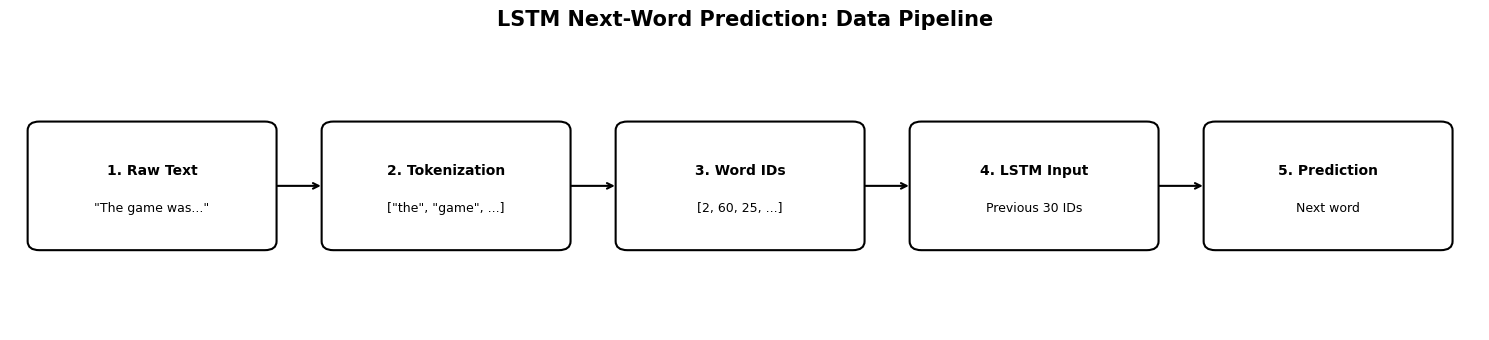

In [29]:
# visualizing the workflow
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15, 3.5))
ax.set_xlim(0, 15)
ax.set_ylim(0, 4)
ax.axis("off")

steps = [
    ("1. Raw Text", '"The game was..."'),
    ("2. Tokenization", '["the", "game", ...]'),
    ("3. Word IDs", "[2, 60, 25, ...]"),
    ("4. LSTM Input", "Previous 30 IDs"),
    ("5. Prediction", "Next word"),
]

positions = [0.3, 3.3, 6.3, 9.3, 12.3]

for i, ((title, detail), x) in enumerate(zip(steps, positions)):
    box = FancyBboxPatch(
        (x, 1.2), 2.3, 1.5,
        boxstyle="round,pad=0.12",
        edgecolor="black",
        facecolor="white",
        linewidth=1.5,
    )
    ax.add_patch(box)
    ax.text(x + 1.15, 2.15, title, ha="center",
            va="center", fontsize=10, weight="bold")
    ax.text(x + 1.15, 1.65, detail, ha="center",
            va="center", fontsize=9)

    if i < len(positions) - 1:
        ax.annotate(
            "",
            xy=(positions[i + 1] - 0.1, 1.95),
            xytext=(x + 2.4, 1.95),
            arrowprops=dict(arrowstyle="->", lw=1.5),
        )

ax.set_title(
    "LSTM Next-Word Prediction: Data Pipeline",
    fontsize=15,
    weight="bold",
)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 25126 (\N{CJK UNIFIED IDEOGRAPH-6226}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 22580 (\N{CJK UNIFIED IDEOGRAPH-5834}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12398 (\N{HIRAGANA LETTER NO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12532 (\N{KATAKANA LETTER VU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12449 (\N{KATAKANA LETTER SMALL A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes

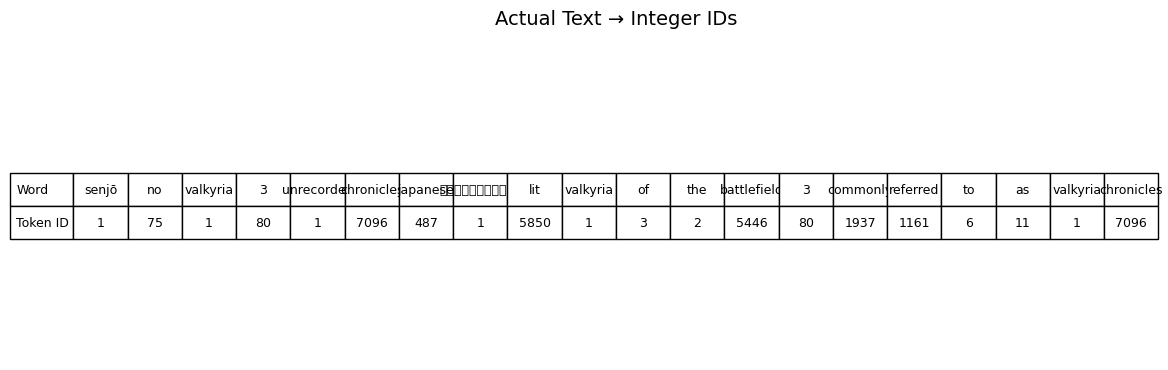

In [30]:
# Their actual words and their ids
sample_text = dataset["train"][1]["text"]
sample_words = tokenize(sample_text)[:20]
sample_ids = [word_to_id.get(w, word_to_id["<UNK>"])
              for w in sample_words]

fig, ax = plt.subplots(figsize=(14, 4))
ax.axis("off")

table_data = [
    sample_words,
    sample_ids,
]

table = ax.table(
    cellText=table_data,
    rowLabels=["Word", "Token ID"],
    loc="center",
    cellLoc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 2)

ax.set_title("Actual Text → Integer IDs", fontsize=14, pad=20)
plt.show()

In [31]:
# printing the data of test to see it


In [32]:

for sentence in dataset['test']:
  print(sentence)


{'text': 'Robert Boulter'}
{'text': 'Robert Boulter is an English film , television and theatre actor . He had a guest - starring role on the television series The Bill in 2000 . This was followed by a starring role in the play Herons written by Simon Stephens , which was performed in 2001 at the Royal Court Theatre . He had a guest role in the television series Judge John Deed in 2002 . In 2004 Boulter landed a role as " Craig " in the episode " Teddy \'s Story " of the television series The Long Firm ; he starred alongside actors Mark Strong and Derek Jacobi . He was cast in the 2005 theatre productions of the Philip Ridley play Mercury Fur , which was performed at the Drum Theatre in Plymouth and the Menier Chocolate Factory in London . He was directed by John Tiffany and starred alongside Ben Whishaw , Shane Zaza , Harry Kent , Fraser Ayres , Sophie Stanton and Dominic Hall .'}
{'text': 'In 2006 , Boulter starred alongside Whishaw in the play Citizenship written by Mark Ravenhill .

In [34]:
import numpy as np
from pathlib import Path
from tensorflow.keras.preprocessing.sequence import pad_sequences

SEQ_LEN = 30
STRIDE = 3
SHARD_SIZE = 100_000

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/NextWordPredictor/processed"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PAD_ID = word_to_id["<PAD>"]
UNK_ID = word_to_id["<UNK>"]

print("Sequence length:", SEQ_LEN)
print("Stride:", STRIDE)
print("Output directory:", OUTPUT_DIR)

Sequence length: 30
Stride: 3
Output directory: /content/drive/MyDrive/NextWordPredictor/processed


In [35]:
def prepare_and_save_split(
    split,
    stride=STRIDE,
    seq_len=SEQ_LEN,
    shard_size=SHARD_SIZE,
):
    split_dir = OUTPUT_DIR / split
    split_dir.mkdir(parents=True, exist_ok=True)

    X_buffer = []
    y_buffer = []

    total_examples = 0
    shard_index = 0

    for row in dataset[split]:
        token_ids = encode_text(row["text"])

        # Predict each selected word from its preceding context.
        for target_pos in range(1, len(token_ids), stride):
            context = token_ids[max(0, target_pos - seq_len):target_pos]
            target = token_ids[target_pos]

            # Make every input exactly SEQ_LEN tokens long.
            padded_context = pad_sequences(
                [context],
                maxlen=seq_len,
                padding="pre",
                truncating="pre",
                value=PAD_ID,
                dtype="int32",
            )[0]

            X_buffer.append(padded_context)
            y_buffer.append(target)

            # Save a shard when the buffer is full.
            if len(X_buffer) >= shard_size:
                np.savez_compressed(
                    split_dir / f"shard_{shard_index:04d}.npz",
                    X=np.asarray(X_buffer, dtype=np.int32),
                    y=np.asarray(y_buffer, dtype=np.int32),
                )

                total_examples += len(y_buffer)
                shard_index += 1

                X_buffer.clear()
                y_buffer.clear()

                if shard_index % 10 == 0:
                    print(
                        f"{split}: saved {total_examples:,} examples"
                    )

    # Save the final partial shard.
    if X_buffer:
        np.savez_compressed(
            split_dir / f"shard_{shard_index:04d}.npz",
            X=np.asarray(X_buffer, dtype=np.int32),
            y=np.asarray(y_buffer, dtype=np.int32),
        )

        total_examples += len(y_buffer)
        shard_index += 1

    print(f"\nFinished {split}")
    print("Total examples:", f"{total_examples:,}")
    print("Shard files:", shard_index)
    print("Saved to:", split_dir)

    return total_examples

In [36]:
train_examples = prepare_and_save_split("train")

train: saved 1,000,000 examples
train: saved 2,000,000 examples
train: saved 3,000,000 examples
train: saved 4,000,000 examples
train: saved 5,000,000 examples
train: saved 6,000,000 examples
train: saved 7,000,000 examples
train: saved 8,000,000 examples
train: saved 9,000,000 examples
train: saved 10,000,000 examples
train: saved 11,000,000 examples
train: saved 12,000,000 examples
train: saved 13,000,000 examples
train: saved 14,000,000 examples
train: saved 15,000,000 examples
train: saved 16,000,000 examples
train: saved 17,000,000 examples
train: saved 18,000,000 examples
train: saved 19,000,000 examples
train: saved 20,000,000 examples
train: saved 21,000,000 examples
train: saved 22,000,000 examples
train: saved 23,000,000 examples
train: saved 24,000,000 examples
train: saved 25,000,000 examples
train: saved 26,000,000 examples
train: saved 27,000,000 examples
train: saved 28,000,000 examples

Finished train
Total examples: 28,834,960
Shard files: 289
Saved to: /content/drive/

In [37]:
train_dir = OUTPUT_DIR / "train"

shard_files = sorted(train_dir.glob("shard_*.npz"))

print("Number of saved files:", len(shard_files))

with np.load(shard_files[0]) as data:
    X_sample = data["X"]
    y_sample = data["y"]

print("X shape:", X_sample.shape)
print("y shape:", y_sample.shape)

print("\nFirst input:")
print([id_to_word[int(i)] for i in X_sample[0]])

print("\nFirst target:")
print(id_to_word[int(y_sample[0])])

Number of saved files: 289
X shape: (100000, 30)
y shape: (100000,)

First input:
['<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<UNK>']

First target:
chronicles


In [38]:
# verifying the things
import numpy as np
from pathlib import Path

train_dir = Path(
    "/content/drive/MyDrive/NextWordPredictor/processed/train"
)

files = sorted(train_dir.glob("shard_*.npz"))

with np.load(files[0]) as data:
    X = data["X"]
    y = data["y"]

pad_id = word_to_id["<PAD>"]
unk_id = word_to_id["<UNK>"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X dtype:", X.dtype)
print("y dtype:", y.dtype)
print("X contains NaN:", np.isnan(X).any())
print("y contains NaN:", np.isnan(y).any())
print("All targets in vocabulary:", np.all((y >= 0) & (y < len(word_to_id))))
print("First input non-PAD tokens:", np.count_nonzero(X[0] != pad_id))
print("First input UNK tokens:", np.count_nonzero(X[0] == unk_id))
print("First target:", id_to_word[int(y[0])])

X shape: (100000, 30)
y shape: (100000,)
X dtype: int32
y dtype: int32
X contains NaN: False
y contains NaN: False
All targets in vocabulary: True
First input non-PAD tokens: 1
First input UNK tokens: 1
First target: chronicles


In [42]:
import os

processed_dir = "/content/drive/MyDrive/NextWordPredictor/processed"
train_dir = os.path.join(processed_dir, "train")

shard_files = sorted([
    os.path.join(train_dir, f)
    for f in os.listdir(train_dir)
    if f.endswith(".npz")
])

print("Total shards:", len(shard_files))
print("First file:", shard_files[0])

Total shards: 289
First file: /content/drive/MyDrive/NextWordPredictor/processed/train/shard_0000.npz


In [43]:
import numpy as np

data = np.load(shard_files[0])

X = data["X"]
y = data["y"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFirst 5 X samples:")
print(X[:5])

print("\nFirst 5 y values:")
print(y[:5])

X shape: (100000, 30)
y shape: (100000,)

First 5 X samples:
[[   0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    1]
 [   0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    1]
 [   0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    1   75
     1   80]
 [   0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    1   75    1   80    1
  7096  487]
 [   0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    1   75    1   80    1 7096  487    1
  5850    1]]

First 5 y values:
[7096   75    1    1    3]


In [46]:
# archietcure of the model
print("Hello world ")

Hello world 


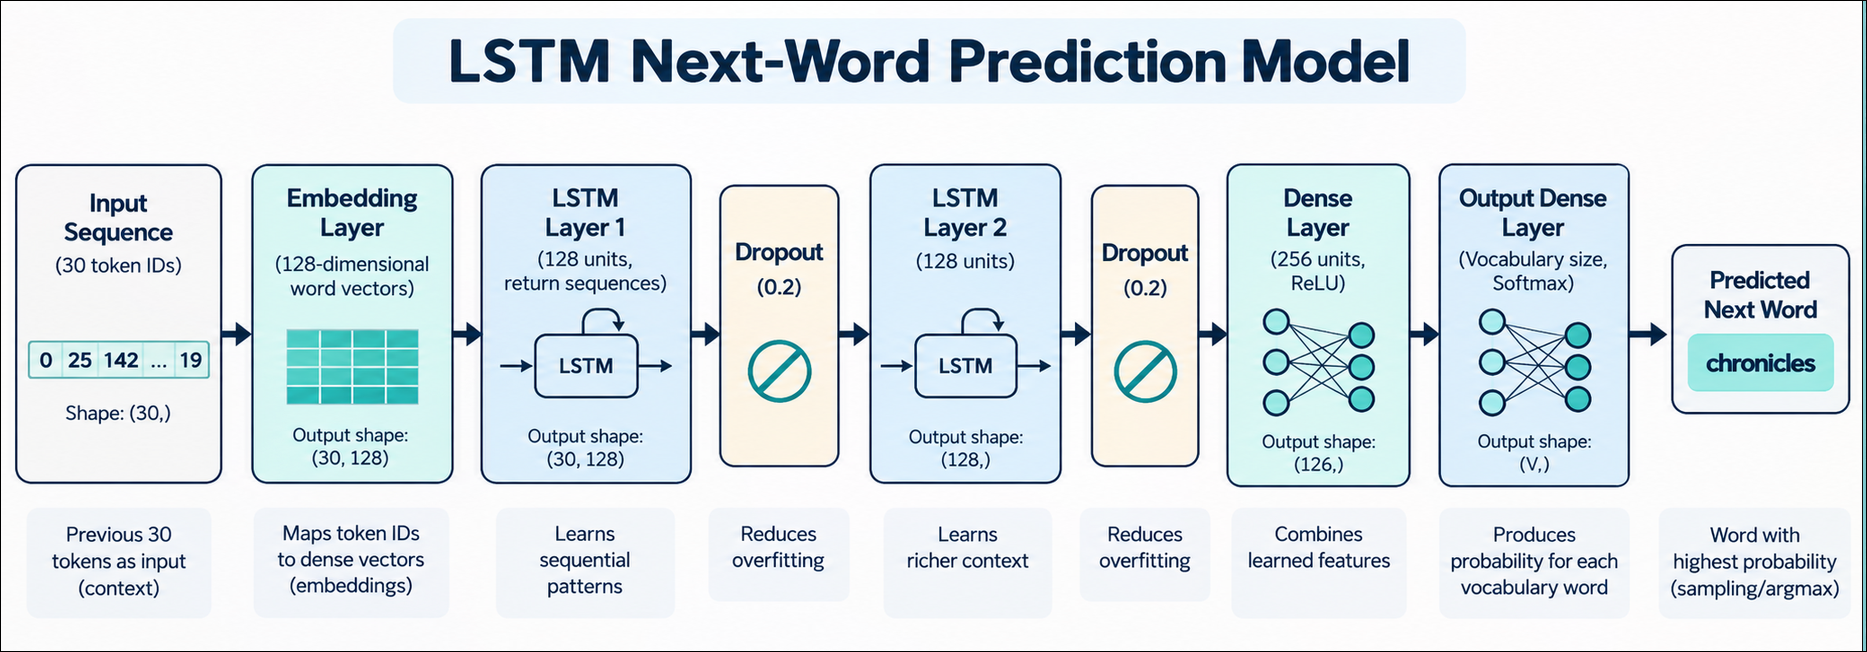

| Layer | Configuration | Purpose |
|---|---|---|
| Input | 30 token IDs | Takes the previous 30 tokens as context. |
| Embedding | 128 dimensions | Converts each token ID into a 128-dimensional vector. |
| LSTM 1 | 128 units | Learns sequential patterns from the input. |
| Dropout 1 | 0.2 | Helps reduce overfitting during training. |
| LSTM 2 | 128 units | Learns richer contextual patterns from the sequence. |
| Dropout 2 | 0.2 | Further helps reduce overfitting. |
| Dense | 256 units, ReLU | Combines learned features to help predict the next token. |
| Output Dense | Vocabulary size, Softmax | Produces a probability distribution over the vocabulary. |
| Prediction | Highest-probability token | Selects the predicted next word. |

In [53]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dropout, Dense

VOCAB_SIZE = len(word_to_id)
SEQ_LEN = 30

model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=128,
        mask_zero=True
    ),

    LSTM(
        128,
        return_sequences=True,
        use_cudnn=False
    ),
    Dropout(0.2),

    LSTM(
        128,
        use_cudnn=False
    ),
    Dropout(0.2),

    Dense(256, activation="relu"),
    Dense(VOCAB_SIZE, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.build(input_shape=(None, SEQ_LEN))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 30, 128)        │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 30, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 30000)          │     7,710,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,846,192 (45.19 MB)

 Trainable params: 11,846,192 (45.19 MB)

 Non-trainable params: 0 (0.00 B)

In [54]:
print("Vocabulary size:", VOCAB_SIZE)
print("Sequence length:", SEQ_LEN)
print("Total parameters:", model.count_params())

Vocabulary size: 30000
Sequence length: 30
Total parameters: 11846192


In [62]:
# full dataset traning
import os
import glob
import math
import numpy as np
import tensorflow as tf

TRAIN_DIR = "/content/drive/MyDrive/NextWordPredictor/processed/train"
MODEL_DIR = "/content/drive/MyDrive/NextWordPredictor/checkpoints"

os.makedirs(MODEL_DIR, exist_ok=True)

shard_files = sorted(
    glob.glob(os.path.join(TRAIN_DIR, "*.npz"))
)

BATCH_SIZE = 128
EPOCHS = 50

print("Total shards:", len(shard_files))
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Total shards: 289
Batch size: 128
Epochs: 50


In [63]:
# training data pipleine
def training_generator(files):
    rng = np.random.default_rng()

    for file in files:
        with np.load(file) as data:
            X = data["X"]
            y = data["y"]

            # Shuffle inputs and their corresponding targets together
            indices = rng.permutation(len(X))

            for start in range(0, len(indices), BATCH_SIZE):
                batch_indices = indices[start:start + BATCH_SIZE]

                yield (
                    X[batch_indices].astype(np.int32, copy=False),
                    y[batch_indices].astype(np.int32, copy=False)
                )


train_dataset = tf.data.Dataset.from_generator(
    lambda: training_generator(shard_files),
    output_signature=(
        tf.TensorSpec(shape=(None, SEQ_LEN), dtype=tf.int32),
        tf.TensorSpec(shape=(None,), dtype=tf.int32)
    )
).prefetch(tf.data.AUTOTUNE)

# Calculate the exact number of batches across all shards
total_examples = 0
steps_per_epoch = 0

for file in shard_files:
    with np.load(file) as data:
        n = len(data["y"])

    total_examples += n
    steps_per_epoch += math.ceil(n / BATCH_SIZE)

print("Total examples:", f"{total_examples:,}")
print("Steps per epoch:", f"{steps_per_epoch:,}")

Total examples: 28,834,960
Steps per epoch: 225,490


In [64]:
# check points
checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(
        MODEL_DIR,
        "lstm_epoch_{epoch:02d}.keras"
    ),
    save_best_only=False,
    save_freq="epoch",
    verbose=1
)

csv_callback = tf.keras.callbacks.CSVLogger(
    os.path.join(MODEL_DIR, "training_log.csv"),
    append=True
)

In [ ]:
# full traning
history = model.fit(
    train_dataset,
    epochs=EPOCHS,
    steps_per_epoch=steps_per_epoch,
    callbacks=[
        checkpoint_callback,
        csv_callback
    ],
    verbose=1
)

Epoch 1/50
225490/225490 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.1555 - loss: 6.2148
Epoch 1: saving model to /content/drive/MyDrive/NextWordPredictor/checkpoints/lstm_epoch_01.keras

Epoch 1: finished saving model to /content/drive/MyDrive/NextWordPredictor/checkpoints/lstm_epoch_01.keras
225490/225490 ━━━━━━━━━━━━━━━━━━━━ 3142s 14ms/step - accuracy: 0.1703 - loss: 5.9596
Epoch 2/50

Epoch 2: saving model to /content/drive/MyDrive/NextWordPredictor/checkpoints/lstm_epoch_02.keras

Epoch 2: finished saving model to /content/drive/MyDrive/NextWordPredictor/checkpoints/lstm_epoch_02.keras
225490/225490 ━━━━━━━━━━━━━━━━━━━━ 1s 5us/step - accuracy: 0.0000e+00 - loss: 0.0000e+00
Epoch 3/50
225487/225490 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.1862 - loss: 5.6440
Epoch 3: saving model to /content/drive/MyDrive/NextWordPredictor/checkpoints/lstm_epoch_03.keras

Epoch 3: finished saving model to /content/drive/MyDrive/NextWordPredictor/checkpoints/lstm_epoch_03.keras
225490/225